# Entrega final — Consolidación, interpretación y comunicación
### Proyecto Integrador · Machine Learning I · Universidad Externado de Colombia
**Localización interior mediante RSSI WiFi y kNN — reconstrucción del artículo QA-kNN (Ferreira et al., 2020)**
**Sebastián Ramos · Daniel Cipagauta**

Este notebook es el anexo de código de la Entrega final. Corre de principio a fin con `SEED = 42`, genera las figuras (`figuras_final/`), las cifras (`resultados_final.json`) y el **modelo desplegado** (`modelo/`), que usa la aplicación `app.py`.

| Sección | Contenido | Guía |
|---|---|---|
| 1 | Qué cambió desde la Entrega 2 | Corrección acumulativa |
| 2 | Simulación recalibrada: dispersión igual a la real | 2.4 |
| 3 | Dataset final y partición por días | 2.1 |
| 4 | Comparación de modelos: del curso (eje) y exploración | 2.1 |
| 5 | Estabilidad entre réplicas de la simulación | 2.1 |
| 6 | Selección (por validación cruzada) y configuración del modelo final | 2.1 |
| 7 | Reproducción de los objetivos del artículo (incl. Método II) | 2.1 |
| 8 | Interpretación del modelo final | 2.2 |
| 9 | Robustez y sensibilidad al supuesto de las paredes | 2.4 |
| 10 | Modelo desplegado y verificación de coherencia | 2.3 |

**Requisitos:** `pip install -r requirements.txt`. El paquete `qaknn/` (en este repositorio) contiene el simulador y la extracción de cuartiles, compartidos con la aplicación.

**Declaración de uso de IA:** usamos un asistente de IA generativa (Claude, de Anthropic) como apoyo para estructurar el código y revisar la redacción. Todas las decisiones fueron revisadas por el equipo, que puede sustentarlas.

In [1]:
import os, json, time, warnings, urllib.request, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats
import joblib, sklearn

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_score, cross_validate
from sklearn.metrics import accuracy_score, f1_score, make_scorer, confusion_matrix

from qaknn.simulacion import (ZONAS, ZONA_IDX, CENTROS, APS, N_APS, ANCHO, FONDO, Y_CORREDOR, ESCENARIOS,
                              construir_edificio, nivel_medio, lecturas_visita, generar_dataset,
                              extraer_caracteristicas, simular_visita, columnas, SIGMA_DIA)

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
for d in ("figuras_final", "datos", "modelo"):
    os.makedirs(d, exist_ok=True)
RES = {}

GRIS, TINTA, TINTA2 = "#898781", "#0b0b0b", "#52514e"
COL = {"Línea base": GRIS, "kNN": "#2a78d6", "Naive Bayes": "#eb6834", "Logística Ridge (L2)": "#1baf7a",
       "Logística Lasso (L1)": "#008300", "LDA": "#eda100", "QDA": "#e87ba4"}
DEL_CURSO = ["kNN", "Naive Bayes", "Logística Ridge (L2)", "Logística Lasso (L1)"]
EXPLORACION = ["LDA", "QDA"]
FUENTE = {"Real (artículo)": "#2a78d6", "Piloto propio": "#eb6834", "Sim. calibrada": "#1baf7a", "Sim. paredes (E2)": "#6250d6"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 8.5,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2,
                     "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "legend.frameon": False})
def guardar(fig, nombre):
    fig.savefig(f"figuras_final/{nombre}.png", bbox_inches="tight", facecolor="white")

def error_medio_m(y_true, y_pred):
    a = CENTROS[[ZONA_IDX[z] for z in y_true]]; b = CENTROS[[ZONA_IDX[z] for z in y_pred]]
    return float(np.linalg.norm(a - b, axis=1).mean())
def errores_m(y_true, y_pred):
    return np.linalg.norm(CENTROS[[ZONA_IDX[z] for z in y_true]] - CENTROS[[ZONA_IDX[z] for z in y_pred]], axis=1)
SCORING = {"accuracy": "accuracy", "f1_macro": "f1_macro", "error_m": make_scorer(error_medio_m, greater_is_better=False)}
CV = GroupKFold(n_splits=5)

def pipe(modelo, escalar=True):
    return Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("escalar", StandardScaler() if escalar else "passthrough"),
                     ("modelo", modelo)])

def bootstrap(y, yp, fn, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); n = len(y)
    return np.percentile([fn(y[i], yp[i]) for i in (rng.integers(0, n, n) for _ in range(B))], [2.5, 97.5])
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Qué cambió desde la Entrega 2

| Observación de la retroalimentación | Respuesta en la entrega final |
|---|---|
| La dispersión simulada era ~2× la real, y eso favorece a los cuartiles | **Recalibramos** la simulación: la fluctuación es ~1 dB en todo el piso, como en los datos reales. El escenario anterior queda como **análisis de sensibilidad** (Sección 9). |
| La cola izquierda se atribuía al artículo | En los datos del artículo la asimetría es +0.10. El escenario calibrado no impone cola; la del escenario «paredes» se declara como supuesto de la literatura. |
| Circularidad de Q1 | Dejamos de presentarlo como hallazgo. En la simulación calibrada la fluctuación es igual en todo el piso, así que Q1 y Q3 tampoco pueden aportar información de obstáculos: ese resultado también sale del generador (Secciones 7 y 8). |
| El titular no debe apoyarse solo en lo simulado | Cada cifra se reporta con su fuente. Agregamos **5 réplicas de la simulación** (mismo plano y APs, distinta sombra; una es la original) y la validación sobre los datos reales del artículo. La medición en nuestro edificio sigue pendiente. |
| LDA, QDA y la regularización no eran del curso | Ridge y Lasso ya se vieron (Sesión 37): ahora la **logística Ridge (L2)** y la **logística Lasso (L1)** son del curso. LDA y QDA siguen como exploración declarada. |

## 2. Simulación recalibrada: la dispersión ahora coincide con la real

In [2]:
RUTA_REAL = "datos_reales_articulo/Wi-FiPowerInOfficeDataset.csv"
if not os.path.exists(RUTA_REAL):
    os.makedirs("datos_reales_articulo", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ferreirad08/DSciBox/master/datasets/"
                               "Wi-FiPowerInOfficeDataset/Wi-FiPowerInOfficeDataset.csv", RUTA_REAL)
real = pd.read_csv(RUTA_REAL)
piloto = pd.concat([pd.read_csv(f) for f in sorted(glob.glob("datos_piloto/*.csv"))], ignore_index=True)

def estad(v):
    v = v[~np.isnan(v)]
    if len(v) < 10 or v.std() == 0: return None
    q1, q3 = np.percentile(v, [25, 75])
    return dict(de=v.std(ddof=1), iqr=q3 - q1, asim=stats.skew(v), ac1=np.corrcoef(v[:-1], v[1:])[0, 1])

t_real = pd.DataFrame([e for rp in range(1, 17) for a in range(8)
                       for b in range(5) if (e := estad(real.loc[real.rp == rp, f"ap{a+1}"].values[b*40:(b+1)*40].astype(float)))])
t_pil = pd.DataFrame([e for _, g in piloto.groupby(["punto", "ap_hash"]) if (e := estad(g.rssi_dbm.values.astype(float)))])
EDIF = construir_edificio(SEED)
t_sim, rango_sim = {}, {}
for esc in ESCENARIOS:
    rng = np.random.default_rng(SEED + 7); filas, todas = [], []
    for _ in range(300):
        A, p = simular_visita(EDIF, ZONAS[rng.integers(len(ZONAS))][0], rng, escenario=esc)
        todas.append(A.ravel())
        for a in range(N_APS):
            e = estad(A[:, a])
            if e: e["paredes"] = nivel_medio(EDIF, p, a)[1]; filas.append(e)
    t_sim[esc] = pd.DataFrame(filas); rango_sim[esc] = np.concatenate(todas)

fuentes = {"Real (artículo)": t_real, "Piloto propio": t_pil, "Sim. calibrada": t_sim["calibrado"], "Sim. paredes (E2)": t_sim["paredes"]}
tabla_cal = pd.DataFrame({k: {"DE temporal mediana (dB)": round(v.de.median(), 2),
                             "IQR temporal mediano (dB)": round(v.iqr.median(), 2),
                             "Asimetría mediana": round(v.asim.median(), 2),
                             "Autocorrelación lag-1": round(v.ac1.median(), 2)} for k, v in fuentes.items()})
tabla_cal.loc["Rango RSSI (dBm)"] = [f"{real.iloc[:, :8].values.min():.0f} a {real.iloc[:, :8].values.max():.0f}",
                                     f"{piloto.rssi_dbm.min():.0f} a {piloto.rssi_dbm.max():.0f}",
                                     f"{np.nanmin(rango_sim['calibrado']):.0f} a {np.nanmax(rango_sim['calibrado']):.0f}",
                                     f"{np.nanmin(rango_sim['paredes']):.0f} a {np.nanmax(rango_sim['paredes']):.0f}"]
RES["calibracion"] = tabla_cal.astype(str).to_dict()
tabla_cal

,Real (artículo),Piloto propio,Sim. calibrada,Sim. paredes (E2)
DE temporal mediana (dB),1.01,0.93,0.95,1.77
IQR temporal mediano (dB),1.0,1.0,1.0,2.0
Asimetría mediana,0.1,-0.35,-0.06,-0.41
Autocorrelación lag-1,0.14,0.15,0.2,0.15
Rango RSSI (dBm),-85 a -27,-93 a -39,-95 a -30,-95 a -30


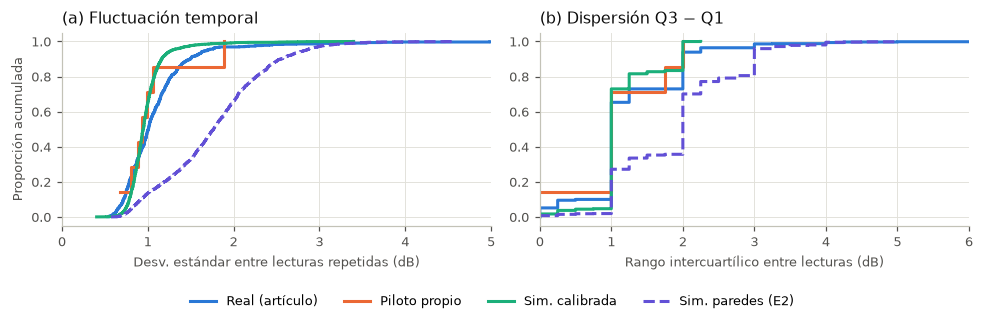

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 2.9))
for nombre, t in fuentes.items():
    ls = "--" if "E2" in nombre else "-"
    for j, col in enumerate(["de", "iqr"]):
        v = np.sort(t[col].dropna().values)
        ax[j].step(v, np.arange(1, len(v)+1) / len(v), where="post", color=FUENTE[nombre], lw=2, ls=ls, label=nombre)
ax[0].set_xlabel("Desv. estándar entre lecturas repetidas (dB)"); ax[0].set_ylabel("Proporción acumulada"); ax[0].set_xlim(0, 5)
ax[1].set_xlabel("Rango intercuartílico entre lecturas (dB)"); ax[1].set_xlim(0, 6)
ax[0].set_title("(a) Fluctuación temporal", loc="left", color=TINTA); ax[1].set_title("(b) Dispersión Q3 − Q1", loc="left", color=TINTA)
h, l = ax[1].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.1, 1, 1)); fig.legend(h, l, loc="lower center", ncol=4)
guardar(fig, "f1_calibracion"); plt.show()

**Lectura.** La simulación calibrada (verde, continua) se superpone a las mediciones reales y al piloto en **todo el piso**, no solo con línea de vista. La de la Entrega 2 (morada, punteada) tenía el doble de dispersión. Desde aquí, el escenario principal es el calibrado. Una cautela: las mediciones reales vienen de una sala pequeña, con línea de vista, y de un piloto de un punto. Que la fluctuación no crezca al cruzar paredes también es un supuesto.

## 3. Dataset final y partición por días

In [4]:
df, EDIF = generar_dataset(n_dias=14, visitas_por_dia=20, m=40, seed=SEED, escenario="calibrado")
FEATS = columnas("cuartiles")
df.to_csv("datos/dataset_final_calibrado.csv", index=False)
X_all = df[FEATS]
RES["calidad"] = dict(instancias=len(df), por_zona=int(df.zona.value_counts().min()), predictores=len(FEATS),
                      celdas_faltantes_pct=round(100 * X_all.isna().mean().mean(), 2),
                      filas_con_faltantes_pct=round(100 * X_all.isna().any(axis=1).mean(), 1),
                      rango=[float(np.nanmin(X_all.values)), float(np.nanmax(X_all.values))],
                      duplicados=int(df.duplicated(subset=FEATS).sum()))
tr, te = df[df.dia <= 10].reset_index(drop=True), df[df.dia > 10].reset_index(drop=True)
Xtr, ytr, gtr, Xte, yte = tr[FEATS], tr.zona.values, tr.dia.values, te[FEATS], te.zona.values
print(RES["calidad"]); print("Entrenamiento", Xtr.shape, "| prueba", Xte.shape)

{'instancias': 5040, 'por_zona': 280, 'predictores': 24, 'celdas_faltantes_pct': np.float64(7.78), 'filas_con_faltantes_pct': np.float64(45.4), 'rango': [-95.0, -27.0], 'duplicados': 0}
Entrenamiento (3600, 24) | prueba (1440, 24)


## 4. Comparación de modelos
El **eje** son los modelos del curso: kNN, Naive Bayes y la regresión logística con regularización Ridge (L2) y Lasso (L1), vista en la Sesión 37. LDA y QDA se mantienen como **exploración declarada**. Todos se ajustan con el mismo Pipeline (imputación → escalado → modelo) y `GridSearchCV` con validación agrupada por día. Además del desempeño, medimos el **tiempo de predicción**, porque es un criterio del despliegue.

In [5]:
MODELOS = {
    "Línea base": (pipe(DummyClassifier(strategy="most_frequent"), False), {}),
    "kNN": (pipe(KNeighborsClassifier()), {"escalar": [StandardScaler(), "passthrough"], "modelo__n_neighbors": list(range(1, 26, 2)),
                                           "modelo__weights": ["uniform", "distance"], "modelo__p": [1, 2]}),
    "Naive Bayes": (pipe(GaussianNB(), False), {"modelo__var_smoothing": list(np.logspace(-9, -1, 9))}),
    "Logística Ridge (L2)": (pipe(LogisticRegression(max_iter=5000)), {"modelo__C": list(np.logspace(-3, 2, 6))}),
    "Logística Lasso (L1)": (pipe(LogisticRegression(l1_ratio=1.0, solver="saga", max_iter=3000, tol=1e-3)),
                             {"modelo__C": [0.1, 0.3, 1.0, 3.0]}),
    "LDA": (pipe(LinearDiscriminantAnalysis(solver="lsqr")), {"modelo__shrinkage": [None, "auto", 0.05, 0.1, 0.2, 0.4]}),
    "QDA": (pipe(QuadraticDiscriminantAnalysis()), {"modelo__reg_param": [0.0, 0.01, 0.05, 0.1, 0.2, 0.4]}),
}
BUSQ, filas = {}, []
for nombre, (modelo, grid) in MODELOS.items():
    t0 = time.time()
    gs = GridSearchCV(modelo, grid, scoring=SCORING, refit="accuracy", cv=CV, n_jobs=1).fit(Xtr, ytr, groups=gtr)
    BUSQ[nombre] = gs; r, i = gs.cv_results_, gs.best_index_
    est = gs.best_estimator_
    t1 = time.perf_counter(); yp = est.predict(Xte); t_pred = (time.perf_counter() - t1) / len(Xte) * 1000
    params = {k.replace("modelo__", ""): (type(v).__name__ if k == "escalar" and v != "passthrough"
                                          else float(v) if isinstance(v, np.floating) else v) for k, v in gs.best_params_.items()}
    filas.append(dict(Modelo=nombre, grupo="curso" if nombre in DEL_CURSO else ("exploración" if nombre in EXPLORACION else "base"),
                      mejores=params, acc=r["mean_test_accuracy"][i], acc_sd=r["std_test_accuracy"][i],
                      f1=r["mean_test_f1_macro"][i], me=-r["mean_test_error_m"][i], me_sd=r["std_test_error_m"][i],
                      folds=[r[f"split{k}_test_accuracy"][i] for k in range(5)],
                      acc_te=accuracy_score(yte, yp), acc_ic=bootstrap(yte, yp, accuracy_score),
                      f1_te=f1_score(yte, yp, average="macro"), me_te=error_medio_m(yte, yp), me_ic=bootstrap(yte, yp, error_medio_m),
                      ms_por_prediccion=t_pred, seg_ajuste=time.time() - t0))
    print(f"{nombre:22s} CV {r['mean_test_accuracy'][i]:.3f} ± {r['std_test_accuracy'][i]:.3f} | prueba {filas[-1]['acc_te']:.3f} | {params} | {time.time()-t0:.0f} s")
resumen = pd.DataFrame(filas)
PRED = {n: BUSQ[n].best_estimator_.predict(Xte) for n in BUSQ}

Línea base             CV 0.056 ± 0.000 | prueba 0.056 | {} | 2 s


kNN                    CV 0.960 ± 0.015 | prueba 0.969 | {'escalar': 'StandardScaler', 'n_neighbors': 1, 'p': 1, 'weights': 'uniform'} | 20 s


Naive Bayes            CV 0.908 ± 0.010 | prueba 0.905 | {'var_smoothing': 0.001} | 3 s


Logística Ridge (L2)   CV 0.917 ± 0.011 | prueba 0.920 | {'C': 10.0} | 8 s


Logística Lasso (L1)   CV 0.915 ± 0.012 | prueba 0.919 | {'C': 3.0} | 81 s


LDA                    CV 0.889 ± 0.014 | prueba 0.891 | {'shrinkage': 'auto'} | 3 s


QDA                    CV 0.934 ± 0.009 | prueba 0.942 | {'reg_param': 0.05} | 3 s


In [6]:
def mcnemar(a, b):
    ok_a, ok_b = PRED[a] == yte, PRED[b] == yte
    n01, n10 = int(np.sum(ok_a & ~ok_b)), int(np.sum(~ok_a & ok_b))
    return n01, n10, float(stats.binomtest(n01, n01 + n10, 0.5).pvalue) if n01 + n10 else 1.0
curso = resumen[resumen.grupo == "curso"].sort_values("acc", ascending=False).Modelo.tolist()
RES["mcnemar"] = {f"{curso[0]} vs {o}": mcnemar(curso[0], o) for o in curso[1:] + EXPLORACION}
RES["comparacion"] = [{k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in f.items()} for f in resumen.drop(columns="folds").to_dict(orient="records")]
vista = pd.DataFrame({"Modelo": resumen.Modelo, "Grupo": resumen.grupo, "Hiperparámetros": resumen.mejores.astype(str),
                      "Accuracy CV": [f"{a:.3f} ± {s:.3f}" for a, s in zip(resumen.acc, resumen.acc_sd)],
                      "Accuracy prueba [IC 95 %]": [f"{a:.3f} [{i[0]:.3f}, {i[1]:.3f}]" for a, i in zip(resumen.acc_te, resumen.acc_ic)],
                      "ME prueba (m)": [f"{a:.2f} [{i[0]:.2f}, {i[1]:.2f}]" for a, i in zip(resumen.me_te, resumen.me_ic)],
                      "ms / predicción": resumen.ms_por_prediccion.round(3)})
print(json.dumps(RES["mcnemar"], indent=1)); vista

{
 "kNN vs Log\u00edstica Ridge (L2)": [
  90,
  20,
  8.637551655996456e-12
 ],
 "kNN vs Log\u00edstica Lasso (L1)": [
  90,
  19,
  3.098472966432261e-12
 ],
 "kNN vs Naive Bayes": [
  116,
  24,
  1.1506721740809353e-15
 ],
 "kNN vs LDA": [
  131,
  19,
  9.06036169351255e-22
 ],
 "kNN vs QDA": [
  62,
  23,
  2.7713609491245692e-05
 ]
}


,Modelo,Grupo,Hiperparámetros,Accuracy CV,Accuracy prueba [IC 95 %],ME prueba (m),ms / predicción
0,Línea base,base,{},0.056 ± 0.000,"0.056 [0.044, 0.067]","15.23 [14.86, 15.62]",0.001
1,kNN,curso,"{'escalar': 'StandardScaler', 'n_neighbors': 1...",0.960 ± 0.015,"0.969 [0.959, 0.978]","0.19 [0.13, 0.25]",0.035
2,Naive Bayes,curso,{'var_smoothing': 0.001},0.908 ± 0.010,"0.905 [0.889, 0.919]","0.56 [0.46, 0.66]",0.003
3,Logística Ridge (L2),curso,{'C': 10.0},0.917 ± 0.011,"0.920 [0.905, 0.933]","0.49 [0.40, 0.59]",0.002
4,Logística Lasso (L1),curso,{'C': 3.0},0.915 ± 0.012,"0.919 [0.905, 0.933]","0.49 [0.39, 0.59]",0.002
5,LDA,exploración,{'shrinkage': 'auto'},0.889 ± 0.014,"0.891 [0.875, 0.905]","0.63 [0.54, 0.74]",0.002
6,QDA,exploración,{'reg_param': 0.05},0.934 ± 0.009,"0.942 [0.928, 0.953]","0.37 [0.28, 0.46]",0.005


## 5. Estabilidad: ¿depende de una sombra particular?
Repetimos el entrenamiento y la prueba, con los hiperparámetros elegidos, en **cinco réplicas de la simulación**: mismo plano y mismos APs, con otra sombra espacial (una de las cinco es la original, semilla 42). Esto mide cuánto depende el resultado del azar de la simulación; no prueba que se sostenga en otro edificio. La variabilidad entre pliegues de la validación se reporta aparte, en la Sección 6.

In [7]:
SEMILLAS = [42, 7, 123, 2024, 31415]
estab = []
for s in SEMILLAS:
    d_s, _ = generar_dataset(seed=s, escenario="calibrado")
    a_, b_ = d_s[d_s.dia <= 10], d_s[d_s.dia > 10]
    for nombre in [n for n in BUSQ if n != "Línea base"]:
        m = sklearn.base.clone(BUSQ[nombre].best_estimator_).fit(a_[FEATS], a_.zona)
        yp = m.predict(b_[FEATS])
        estab.append(dict(semilla=s, Modelo=nombre, acc=accuracy_score(b_.zona, yp), me=error_medio_m(b_.zona.values, yp)))
estab = pd.DataFrame(estab)
piv_e = estab.pivot(index="Modelo", columns="semilla", values="acc")
piv_e["media"], piv_e["DE"] = piv_e.mean(axis=1), piv_e.std(axis=1)
piv_e["veces 1.º"] = [(estab.loc[estab.groupby("semilla").acc.idxmax(), "Modelo"] == n).sum() for n in piv_e.index]
RES["estabilidad"] = piv_e.round(4).reset_index().to_dict(orient="list")
piv_e.sort_values("media", ascending=False).round(3)

semilla,7,42,123,2024,31415,media,DE,veces 1.º
Modelo,,,,,,,,
kNN,0.974,0.969,0.967,0.976,0.981,0.973,0.006,5
QDA,0.947,0.942,0.944,0.951,0.958,0.949,0.007,0
Logística Lasso (L1),0.940,0.919,0.926,0.928,0.923,0.927,0.008,0
Logística Ridge (L2),0.940,0.920,0.924,0.928,0.920,0.926,0.008,0
Naive Bayes,0.924,0.905,0.914,0.916,0.921,0.916,0.007,0
LDA,0.910,0.891,0.859,0.900,0.903,0.893,0.020,0


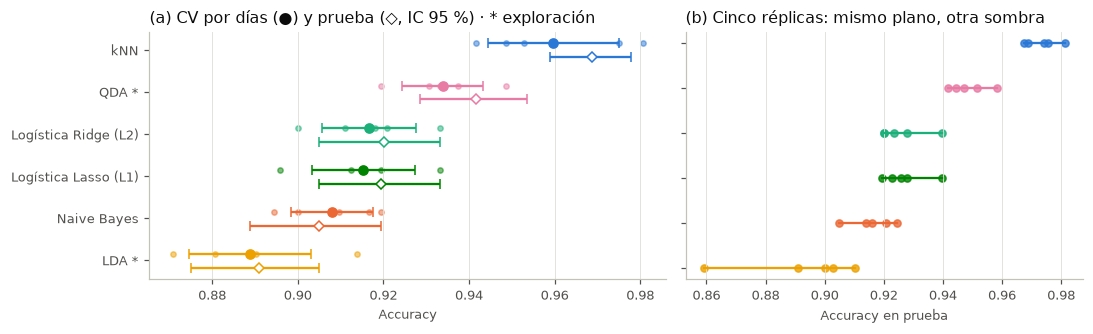

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.1), gridspec_kw=dict(width_ratios=[1.3, 1]))
orden = [n for n in resumen.sort_values("acc").Modelo if n != "Línea base"]
for i, n in enumerate(orden):
    f = resumen[resumen.Modelo == n].iloc[0]
    ax[0].scatter(f.folds, [i + 0.15] * 5, s=12, color=COL[n], alpha=0.5)
    ax[0].errorbar(f.acc, i + 0.15, xerr=f.acc_sd, fmt="o", ms=6, color=COL[n], capsize=3)
    ax[0].errorbar(f.acc_te, i - 0.18, xerr=[[f.acc_te - f.acc_ic[0]], [f.acc_ic[1] - f.acc_te]], fmt="D", ms=5, mfc="white", color=COL[n], capsize=3)
ax[0].set_yticks(range(len(orden)), [f"{n}{' *' if n in EXPLORACION else ''}" for n in orden])
ax[0].set_xlabel("Accuracy"); ax[0].grid(axis="y", visible=False)
ax[0].set_title("(a) CV por días (●) y prueba (◇, IC 95 %) · * exploración", loc="left", color=TINTA)
for i, n in enumerate(orden):
    v = estab[estab.Modelo == n].acc.values
    ax[1].scatter(v, [i] * len(v), s=22, color=COL[n], alpha=0.8)
    ax[1].plot([v.min(), v.max()], [i, i], color=COL[n], lw=1.5)
ax[1].set_yticks(range(len(orden)), []); ax[1].set_xlabel("Accuracy en prueba"); ax[1].grid(axis="y", visible=False)
ax[1].set_title("(b) Cinco réplicas: mismo plano, otra sombra", loc="left", color=TINTA)
fig.tight_layout(); guardar(fig, "f2_comparacion"); plt.show()

## 6. Selección del modelo final
Decidimos con métricas, estabilidad y el equilibrio entre desempeño e interpretabilidad, solo entre modelos del curso. **El criterio de selección es el acierto en validación cruzada agrupada por días.** Las columnas de prueba se muestran para confirmar la decisión; no intervienen en ella.

In [9]:
sel = resumen[resumen.grupo == "curso"].set_index("Modelo")
decision = pd.DataFrame({
    "Accuracy CV": sel.acc.round(3),
    "DE entre pliegues": sel.acc_sd.round(3),
    "Accuracy prueba": sel.acc_te.round(3),
    "ME prueba (m)": sel.me_te.round(2),
    "Accuracy media en 5 réplicas": piv_e.loc[sel.index, "media"].round(3),
    "DE entre réplicas": piv_e.loc[sel.index, "DE"].round(3),
    "ms / predicción": sel.ms_por_prediccion.round(3),
    "Interpretabilidad": ["Media: vecinos y mapa de errores" if n == "kNN" else
                          "Alta: coeficientes por zona" if "Logística" in n else "Media: medias y varianzas por zona" for n in sel.index],
}).sort_values("Accuracy CV", ascending=False)
FINAL = decision.index[0]
RES["decision"] = decision.reset_index().astype(str).to_dict(orient="list"); RES["final"] = FINAL
RES["final_params"] = BUSQ[FINAL].best_params_.__repr__()
print("Modelo final:", FINAL, BUSQ[FINAL].best_params_)
decision

Modelo final: kNN {'escalar': StandardScaler(), 'modelo__n_neighbors': 1, 'modelo__p': 1, 'modelo__weights': 'uniform'}


,Accuracy CV,DE entre pliegues,Accuracy prueba,ME prueba (m),Accuracy media en 5 réplicas,DE entre réplicas,ms / predicción,Interpretabilidad
Modelo,,,,,,,,
kNN,0.960,0.015,0.969,0.19,0.973,0.006,0.035,Media: vecinos y mapa de errores
Logística Ridge (L2),0.917,0.011,0.920,0.49,0.926,0.008,0.002,Alta: coeficientes por zona
Logística Lasso (L1),0.915,0.012,0.919,0.49,0.927,0.008,0.002,Alta: coeficientes por zona
Naive Bayes,0.908,0.010,0.905,0.56,0.916,0.007,0.003,Media: medias y varianzas por zona


In [10]:
# Supuesto que separa a LDA de QDA: ¿todas las zonas tienen la misma varianza? (solo entrenamiento)
lev_p, razon_de = [], []
for f in FEATS:
    grupos = [tr.loc[tr.zona == z[0], f].dropna().values for z in ZONAS]
    lev_p.append(stats.levene(*grupos, center="median").pvalue)
    de = [g.std(ddof=1) for g in grupos]; razon_de.append(max(de) / min(de))
RES["supuesto_covarianza"] = dict(levene_rechazo_pct=round(100 * float(np.mean(np.array(lev_p) < 0.05)), 1),
                                  razon_DE_max_min_mediana=round(float(np.median(razon_de)), 2))
print(RES["supuesto_covarianza"])


{'levene_rechazo_pct': 100.0, 'razon_DE_max_min_mediana': 2.59}


## 7. Reproducción de los objetivos del artículo
**7.1 Número de APs × k** (Tabla 3 del artículo) con el modelo final.

In [11]:
bp = BUSQ["kNN"].best_params_
barr = []
for n in range(2, 9):
    cols = columnas("cuartiles", range(1, n + 1))
    for k in range(1, 14, 2):
        m = pipe(KNeighborsClassifier(n_neighbors=k, p=bp["modelo__p"], weights=bp["modelo__weights"]), bp["escalar"] != "passthrough")
        s = cross_validate(m, tr[cols], ytr, groups=gtr, cv=CV, scoring=SCORING)
        barr.append(dict(n=n, k=k, acc=s["test_accuracy"].mean(), me=-s["test_error_m"].mean()))
barr = pd.DataFrame(barr); RES["barrido_nk"] = barr.round(4).values.tolist()
print(barr.pivot(index="n", columns="k", values="me").round(2))

k    1     3     5     7     9     11    13
n                                          
2  6.79  6.85  6.44  6.36  6.20  6.14  6.15
3  4.16  3.94  3.81  3.69  3.72  3.68  3.66
4  2.60  2.48  2.35  2.34  2.39  2.40  2.42
5  1.47  1.49  1.48  1.49  1.52  1.51  1.54
6  0.58  0.61  0.58  0.62  0.65  0.68  0.70
7  0.34  0.38  0.39  0.41  0.42  0.44  0.44
8  0.24  0.29  0.29  0.30  0.33  0.35  0.37


**7.2 Cuartiles frente a representaciones más simples**, en la simulación calibrada, en el escenario de la Entrega 2 y en los datos reales del artículo.

In [12]:
reps = {"Lectura cruda": "cruda", "Media": "media", "Mediana (Q2)": "mediana", "Cuartiles Q1–Q3": "cuartiles"}
knn_f = lambda k=bp["modelo__n_neighbors"]: pipe(KNeighborsClassifier(n_neighbors=k, p=bp["modelo__p"]), bp["escalar"] != "passthrough")
df_par, _ = generar_dataset(seed=SEED, escenario="paredes"); tr_par = df_par[df_par.dia <= 10]
def instancias_reales(m=10):
    filas = []
    for rp in range(1, 17):
        v = real[real.rp == rp].iloc[:, :8].values.astype(float)
        for b in range(len(v) // m):
            f = extraer_caracteristicas(v[b*m:(b+1)*m]); f.update(rp=rp, bloque=b); filas.append(f)
    return pd.DataFrame(filas)
R = instancias_reales(10)
rep_res = []
for fuente, (d_, y_, g_, k_) in {"Sim. calibrada": (tr, "zona", "dia", None), "Sim. paredes (E2)": (tr_par, "zona", "dia", None),
                                 "Real (artículo)": (R, "rp", "bloque", 1)}.items():
    for n in [2, 3, 4, 8]:
        for et, rep in reps.items():
            s = cross_val_score(knn_f(k_) if k_ else knn_f(), d_[columnas(rep, range(1, n + 1))], d_[y_].values, groups=d_[g_].values, cv=CV)
            rep_res.append(dict(fuente=fuente, n=n, rep=et, acc=s.mean(), folds=s))
rep_res = pd.DataFrame(rep_res)
dif = {f: {n: (lambda a, b: [round((a - b).mean(), 4), round((a - b).std(), 4)])(
            rep_res[(rep_res.fuente == f) & (rep_res.n == n) & (rep_res.rep == "Cuartiles Q1–Q3")].folds.iloc[0],
            rep_res[(rep_res.fuente == f) & (rep_res.n == n) & (rep_res.rep == "Media")].folds.iloc[0]) for n in [2, 3, 4, 8]}
       for f in rep_res.fuente.unique()}
RES["representaciones"] = rep_res.drop(columns="folds").round(4).values.tolist(); RES["dif_cuartiles_media"] = dif
print(rep_res.pivot_table(index=["fuente", "n"], columns="rep", values="acc").round(3)); print(json.dumps(dif, indent=1))

rep                  Cuartiles Q1–Q3  Lectura cruda  Media  Mediana (Q2)
fuente            n                                                     
Real (artículo)   2            0.950          0.720  0.954         0.934
                  3            0.981          0.831  0.987         0.963
                  4            1.000          0.943  1.000         1.000
                  8            1.000          1.000  1.000         1.000
Sim. calibrada    2            0.385          0.334  0.387         0.378
                  3            0.588          0.521  0.592         0.599
                  4            0.720          0.649  0.724         0.716
                  8            0.960          0.940  0.961         0.958
Sim. paredes (E2) 2            0.414          0.333  0.386         0.381
                  3            0.596          0.489  0.599         0.600
                  4            0.716          0.594  0.717         0.711
                  8            0.959          0.896

**7.3 Método I (RP mayoritario) frente a Método II (centroide de los vecinos).** El artículo muestra que, cuando el dispositivo está en posiciones arbitrarias (no en los puntos de referencia), el centroide de los k vecinos reduce el error y mejora al aumentar k. Lo probamos con la **posición real** de cada visita de prueba, que la simulación conoce.

In [13]:
modelo_k = BUSQ["kNN"].best_estimator_
Ztr_ = modelo_k[:-1].transform(Xtr); Zte_ = modelo_k[:-1].transform(Xte)
pos_real = te[["x", "y"]].values
centros_tr = CENTROS[[ZONA_IDX[z] for z in ytr]]
met = []
for k in [1, 3, 5, 9, 15, 25, 41]:
    knn_k = KNeighborsClassifier(n_neighbors=k, p=bp["modelo__p"]).fit(Ztr_, ytr)
    idx = knn_k.kneighbors(Zte_, return_distance=False)
    centroide = centros_tr[idx].mean(axis=1)                     # Método II (Ec. 3 del artículo)
    mayoritario = CENTROS[[ZONA_IDX[z] for z in knn_k.predict(Zte_)]]   # Método I (Ec. 2)
    met.append(dict(k=k, metodo_I=np.linalg.norm(mayoritario - pos_real, axis=1).mean(),
                    metodo_II=np.linalg.norm(centroide - pos_real, axis=1).mean()))
met = pd.DataFrame(met); RES["metodos"] = met.round(3).values.tolist()
met.round(3)

,k,metodo_I,metodo_II
0,1,2.184,2.184
1,3,2.206,2.157
2,5,2.216,2.142
3,9,2.212,2.142
4,15,2.257,2.127
5,25,2.260,2.115
6,41,2.285,2.122


**7.4 Selección de cuartiles con Lasso** — el artículo propone, como trabajo futuro, elegir el cuartil más discriminante para reducir el tamaño del dataset.

In [14]:
lasso_path = []
for C in [0.01, 0.03, 0.1, 0.3, 1.0]:
    m = pipe(LogisticRegression(l1_ratio=1.0, solver="saga", C=C, max_iter=3000, tol=1e-3)).fit(Xtr, ytr)
    activo = np.abs(m.named_steps["modelo"].coef_).max(axis=0) > 1e-8
    coefs = m.named_steps["modelo"].coef_
    fila = dict(C=C, acc_prueba=accuracy_score(yte, m.predict(Xte)), variables=int(activo.sum()),
                coef_no_nulos=int((np.abs(coefs) > 1e-8).sum()), coef_total=int(coefs.size))
    for q in ("Q1", "Q2", "Q3"):
        fila[q] = int(sum(a for a, f in zip(activo, FEATS) if f.endswith(q)))
    lasso_path.append(fila)
lasso_path = pd.DataFrame(lasso_path); RES["lasso_path"] = lasso_path.round(4).values.tolist()
lasso_path

,C,acc_prueba,variables,coef_no_nulos,coef_total,Q1,Q2,Q3
0,0.01,0.698611,23,43,432,8,8,7
1,0.03,0.844444,24,79,432,8,8,8
2,0.10,0.894444,24,131,432,8,8,8
3,0.30,0.906250,24,196,432,8,8,8
4,1.00,0.914583,24,251,432,8,8,8


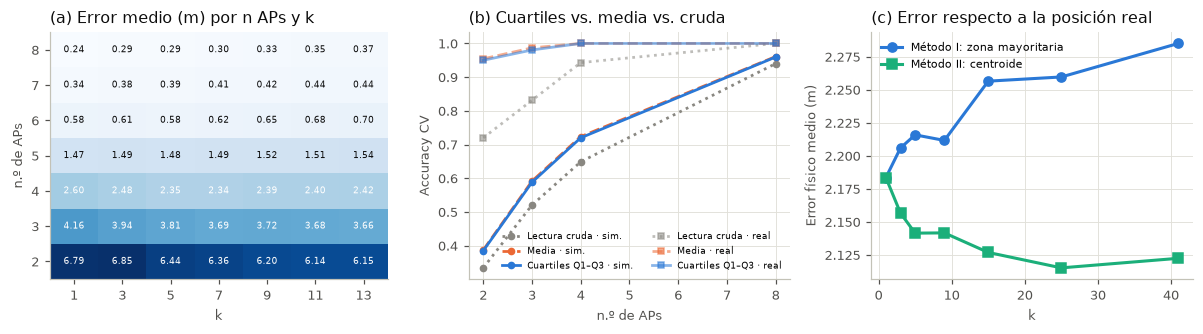

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.1), gridspec_kw=dict(width_ratios=[1.05, 1, 1]))
piv = barr.pivot(index="n", columns="k", values="me")
im = ax[0].imshow(piv.values, cmap="Blues", aspect="auto", origin="lower")
ax[0].set_xticks(range(piv.shape[1]), piv.columns); ax[0].set_yticks(range(piv.shape[0]), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]; ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if v > piv.values.mean() else TINTA)
ax[0].set_xlabel("k"); ax[0].set_ylabel("n.º de APs"); ax[0].grid(False)
ax[0].set_title("(a) Error medio (m) por n APs y k", loc="left", color=TINTA)
est_rep = {"Lectura cruda": ("#898781", ":"), "Media": ("#eb6834", "--"), "Cuartiles Q1–Q3": ("#2a78d6", "-")}
for f_, mk in [("Sim. calibrada", "o"), ("Real (artículo)", "s")]:
    for et, (c, ls) in est_rep.items():
        s = rep_res[(rep_res.fuente == f_) & (rep_res.rep == et)]
        ax[1].plot(s.n, s.acc, ls, marker=mk, ms=4, color=c, lw=1.8, alpha=1 if f_ == "Sim. calibrada" else 0.55,
                   label=f"{et} · {'sim.' if f_ == 'Sim. calibrada' else 'real'}")
ax[1].set_xlabel("n.º de APs"); ax[1].set_ylabel("Accuracy CV"); ax[1].legend(fontsize=6, ncol=2, loc="lower right")
ax[1].set_title("(b) Cuartiles vs. media vs. cruda", loc="left", color=TINTA)
ax[2].plot(met.k, met.metodo_I, "o-", color="#2a78d6", lw=2, label="Método I: zona mayoritaria")
ax[2].plot(met.k, met.metodo_II, "s-", color="#1baf7a", lw=2, label="Método II: centroide")
ax[2].set_xlabel("k"); ax[2].set_ylabel("Error físico medio (m)"); ax[2].legend(fontsize=7)
ax[2].set_title("(c) Error respecto a la posición real", loc="left", color=TINTA)
fig.tight_layout(); guardar(fig, "f3_articulo"); plt.show()

## 8. Interpretación del modelo final

In [16]:
mf = BUSQ[FINAL].best_estimator_; ypf = PRED[FINAL]
err = ypf != yte; e_m = errores_m(yte, ypf)
recall_z = np.array([np.mean(ypf[yte == z[0]] == z[0]) for z in ZONAS])
cm = confusion_matrix(yte, ypf, labels=[z[0] for z in ZONAS])
conf = sorted([(ZONAS[i][0], ZONAS[j][0], int(cm[i, j])) for i in range(18) for j in range(18) if i != j], key=lambda t: -t[2])[:6]
def imp_perm(modelo, X, y, grupos, n_rep=15, seed=SEED):
    rng = np.random.default_rng(seed); base = accuracy_score(y, modelo.predict(X)); out = {}
    for nombre, cols in grupos.items():
        caidas = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[cols] = X[cols].values[rng.permutation(len(X))]; caidas.append(base - accuracy_score(y, modelo.predict(Xp)))
        out[nombre] = (float(np.mean(caidas)), float(np.std(caidas)))
    return out
imp_ap = imp_perm(mf, Xte, yte, {f"AP{a}": [f"AP{a}_Q1", f"AP{a}_Q2", f"AP{a}_Q3"] for a in range(1, 9)})
imp_q = imp_perm(mf, Xte, yte, {q: [f"AP{a}_{q}" for a in range(1, 9)] for q in ("Q1", "Q2", "Q3")})
RES["interpretacion"] = dict(modelo=FINAL, recall_por_zona={z[0]: round(float(r), 3) for z, r in zip(ZONAS, recall_z)},
                             pct_errores_contiguos=round(100 * float(np.mean(e_m[err] <= 6.01)), 1) if err.any() else 0.0,
                             error_si_falla=round(float(e_m[err].mean()), 2) if err.any() else 0.0,
                             errores_prueba=int(err.sum()), errores_no_contiguos=int(np.sum(e_m[err] > 6.01)),
                             error_medio_no_contiguos=round(float(e_m[err][e_m[err] > 6.01].mean()), 2) if np.any(e_m[err] > 6.01) else 0.0,
                             error_max=round(float(e_m[err].max()), 2) if err.any() else 0.0,
                             acc_por_tipo=te.assign(ok=~err).groupby("tipo").ok.mean().round(3).to_dict(),
                             pares_confundidos=conf, importancia_AP=imp_ap, importancia_cuartil=imp_q)
print(json.dumps(RES["interpretacion"], indent=1, ensure_ascii=False))

{
 "modelo": "kNN",
 "recall_por_zona": {
  "Z01": 1.0,
  "Z02": 1.0,
  "Z03": 0.963,
  "Z04": 0.975,
  "Z05": 0.95,
  "Z06": 0.963,
  "Z07": 0.975,
  "Z08": 0.938,
  "Z09": 0.975,
  "Z10": 0.95,
  "Z11": 0.95,
  "Z12": 1.0,
  "Z13": 0.975,
  "Z14": 1.0,
  "Z15": 0.975,
  "Z16": 0.925,
  "Z17": 0.925,
  "Z18": 1.0
 },
 "pct_errores_contiguos": 84.4,
 "error_si_falla": 5.93,
 "errores_prueba": 45,
 "errores_no_contiguos": 7,
 "error_medio_no_contiguos": 11.0,
 "error_max": 13.0,
 "acc_por_tipo": {
  "Aula": 0.975,
  "Corredor": 0.965,
  "Oficina": 0.967
 },
 "pares_confundidos": [
  [
   "Z17",
   "Z18",
   5
  ],
  [
   "Z08",
   "Z07",
   4
  ],
  [
   "Z11",
   "Z10",
   4
  ],
  [
   "Z03",
   "Z04",
   3
  ],
  [
   "Z06",
   "Z04",
   3
  ],
  [
   "Z10",
   "Z11",
   3
  ]
 ],
 "importancia_AP": {
  "AP1": [
   0.10814814814814815,
   0.007061361468495435
  ],
  "AP2": [
   0.08611111111111112,
   0.006627003928621038
  ],
  "AP3": [
   0.08037037037037038,
   0.00547667769987043

Como lectura complementaria e interpretable, los **coeficientes de la logística Lasso** indican qué AP «delata» a cada zona: un coeficiente positivo sobre la mediana (Q2) de un AP significa que una señal más fuerte de ese AP hace más probable la zona. Es una lectura **orientativa**: Q1, Q2 y Q3 de un AP son casi colineales, así que Lasso puede repartir el peso entre ellos de forma poco estable, y aquí solo se muestra Q2.

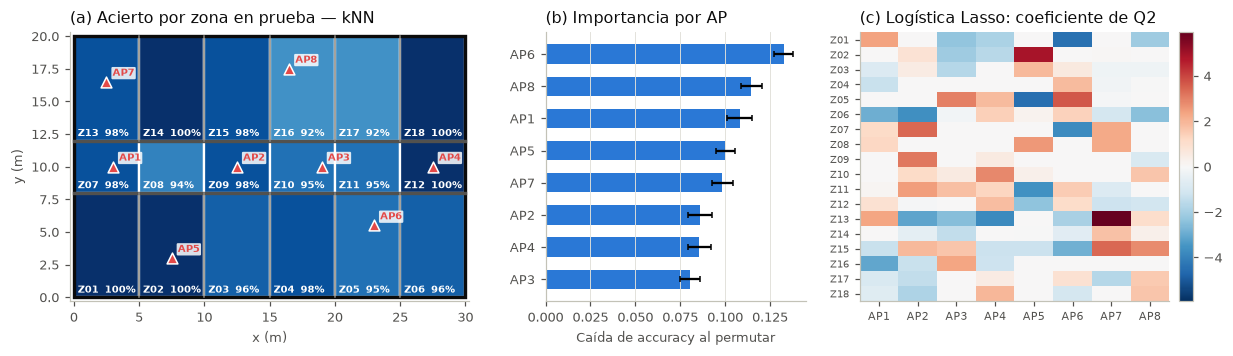

In [17]:
lasso = BUSQ["Logística Lasso (L1)"].best_estimator_
coef = pd.DataFrame(lasso.named_steps["modelo"].coef_, index=lasso.classes_, columns=FEATS)
coef_q2 = coef[[f"AP{a}_Q2" for a in range(1, 9)]]; coef_q2.columns = [f"AP{a}" for a in range(1, 9)]
firma = {z: [f"{c} ({v:+.1f})" for c, v in coef_q2.loc[z].sort_values(ascending=False).head(2).items()] for z in coef_q2.index}
RES["firma_lasso"] = firma
ap_cercano = {z[0]: f"AP{int(np.argmin(np.linalg.norm(APS - CENTROS[ZONA_IDX[z[0]]], axis=1))) + 1}" for z in ZONAS}
RES["lasso_ap_cercano"] = dict(coinciden=int(sum(firma[z][0].split()[0] == ap_cercano[z] for z in ap_cercano)), total=len(ap_cercano))
RES["lasso_activas_por_cuartil"] = {q: int((coef.filter(like=q).abs().max() > 1e-8).sum()) for q in ("Q1", "Q2", "Q3")}
def dibujar_plano(ax, valores=None, cmap=None, vmin=None, vmax=None, fmt="{:.0%}", etiquetas=True):
    tonos = {"Aula": "#eef4fa", "Corredor": "#f4f3ee", "Oficina": "#eaf6f1"}
    for i, (zid, x0, x1, y0, y1, tipo) in enumerate(ZONAS):
        fc = cmap((valores[i] - vmin) / (vmax - vmin)) if valores is not None else tonos[tipo]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=fc, edgecolor="white", lw=1.5))
        if etiquetas:
            oscuro = valores is not None and (valores[i] - vmin) / (vmax - vmin) > 0.55
            ax.text(x0 + 0.3, y0 + 0.35, zid if valores is None else f"{zid}  {fmt.format(valores[i])}", fontsize=6.5,
                    color="white" if oscuro else TINTA2, weight="bold" if valores is not None else "normal")
    for yw in Y_CORREDOR: ax.plot([0, ANCHO], [yw, yw], color=TINTA2, lw=2.2)
    for xw in np.arange(5, ANCHO, 5):
        ax.plot([xw, xw], [0, 8], color=GRIS, lw=1); ax.plot([xw, xw], [12, 20], color=GRIS, lw=1)
    ax.add_patch(Rectangle((0, 0), ANCHO, FONDO, fill=False, edgecolor=TINTA, lw=2.2))
    ax.scatter(APS[:, 0], APS[:, 1], marker="^", s=50, color="#e34948", edgecolor="white", lw=1, zorder=5)
    for i, (x, y) in enumerate(APS):
        ax.annotate(f"AP{i+1}", (x, y), xytext=(4, 4), textcoords="offset points", fontsize=6.5, color="#e34948", weight="bold",
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85))
    ax.set_xlim(-0.3, ANCHO + 0.3); ax.set_ylim(-0.3, FONDO + 0.3); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.3), gridspec_kw=dict(width_ratios=[1.45, 0.85, 1.1]))
dibujar_plano(ax[0], valores=recall_z, cmap=plt.get_cmap("Blues"), vmin=0.8, vmax=1.0)
ax[0].set_title(f"(a) Acierto por zona en prueba — {FINAL}", loc="left", color=TINTA)
o_ap = sorted(imp_ap, key=lambda k: imp_ap[k][0])
ax[1].barh(o_ap, [imp_ap[k][0] for k in o_ap], xerr=[imp_ap[k][1] for k in o_ap], color=COL.get(FINAL, "#2a78d6"), height=0.6, capsize=2)
ax[1].set_xlabel("Caída de accuracy al permutar"); ax[1].grid(axis="y", visible=False)
ax[1].set_title("(b) Importancia por AP", loc="left", color=TINTA)
vmax = np.abs(coef_q2.values).max()
im = ax[2].imshow(coef_q2.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax[2].set_xticks(range(8), coef_q2.columns, fontsize=7); ax[2].set_yticks(range(18), coef_q2.index, fontsize=6.5); ax[2].grid(False)
ax[2].set_title("(c) Logística Lasso: coeficiente de Q2", loc="left", color=TINTA)
fig.colorbar(im, ax=ax[2], fraction=0.05, pad=0.03)
fig.tight_layout(); guardar(fig, "f4_interpretacion"); plt.show()

## 9. Robustez para el despliegue y sensibilidad

{
 "caida_ap": {
  "AP1": 0.8854166666666666,
  "AP2": 0.9097222222222222,
  "AP3": 0.9034722222222222,
  "AP4": 0.9173611111111111,
  "AP5": 0.8888888888888888,
  "AP6": 0.8659722222222223,
  "AP7": 0.8916666666666667,
  "AP8": 0.8791666666666667
 },
 "lecturas": {
  "5": 0.9715277777777778,
  "10": 0.9708333333333333,
  "20": 0.9673611111111111,
  "40": 0.96875
 },
 "sensibilidad": {
  "kNN": {
   "calibrado": 0.96875,
   "paredes": 0.9659722222222222
  },
  "Naive Bayes": {
   "calibrado": 0.9048611111111111,
   "paredes": 0.9027777777777778
  },
  "Log\u00edstica Ridge (L2)": {
   "calibrado": 0.9201388888888888,
   "paredes": 0.9236111111111112
  },
  "Log\u00edstica Lasso (L1)": {
   "calibrado": 0.9194444444444444,
   "paredes": 0.9229166666666667
  },
  "LDA": {
   "calibrado": 0.8909722222222223,
   "paredes": 0.8930555555555556
  },
  "QDA": {
   "calibrado": 0.9416666666666667,
   "paredes": 0.9395833333333333
  }
 }
}


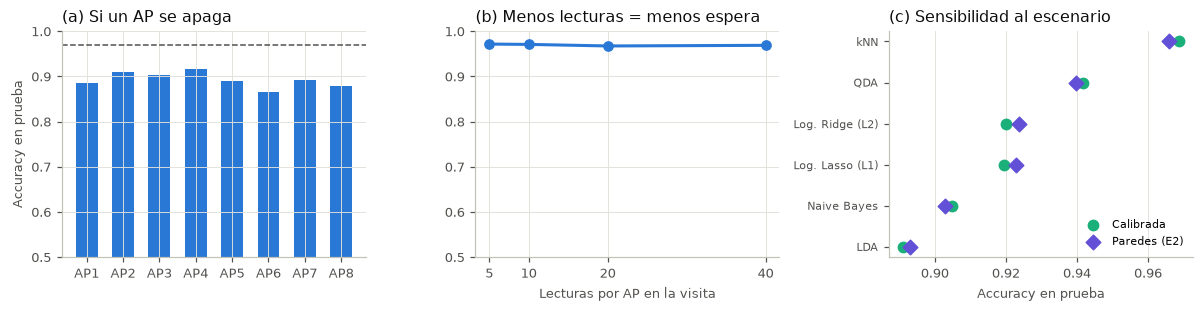

In [18]:
# (a) Un AP deja de funcionar en todas las visitas de prueba
caida_ap = {}
for a in range(1, 9):
    Xc = Xte.copy(); Xc[[f"AP{a}_Q1", f"AP{a}_Q2", f"AP{a}_Q3"]] = np.nan
    caida_ap[f"AP{a}"] = accuracy_score(yte, mf.predict(Xc))
# (b) Menos lecturas por visita (menos espera para el usuario): el modelo se entrena con 40 y se prueba con m
lecturas = {}
for m in [5, 10, 20, 40]:
    d_m, _ = generar_dataset(seed=SEED, m=m, escenario="calibrado")
    t_m = d_m[d_m.dia > 10]
    lecturas[m] = accuracy_score(t_m.zona, mf.predict(t_m[FEATS]))
# (c) Sensibilidad: todo el flujo en el escenario «paredes» de la Entrega 2 (dispersión ≈ 2× la real)
sens = {}
te_par = df_par[df_par.dia > 10]
for nombre in [n for n in BUSQ if n != "Línea base"]:
    m = sklearn.base.clone(BUSQ[nombre].best_estimator_).fit(tr_par[FEATS], tr_par.zona)
    sens[nombre] = dict(calibrado=float(resumen.set_index("Modelo").loc[nombre, "acc_te"]),
                        paredes=accuracy_score(te_par.zona, m.predict(te_par[FEATS])))
RES["robustez"] = dict(caida_ap=caida_ap, lecturas=lecturas, sensibilidad=sens)
print(json.dumps(RES["robustez"], indent=1))

fig, ax = plt.subplots(1, 3, figsize=(11, 2.9))
ax[0].bar(list(caida_ap), list(caida_ap.values()), color="#2a78d6", width=0.6)
ax[0].axhline(resumen.set_index("Modelo").loc[FINAL, "acc_te"], color=TINTA2, ls="--", lw=1)
ax[0].set_ylim(0.5, 1); ax[0].set_ylabel("Accuracy en prueba"); ax[0].set_title("(a) Si un AP se apaga", loc="left", color=TINTA)
ax[1].plot(list(lecturas), list(lecturas.values()), "o-", color="#2a78d6", lw=2)
ax[1].set_xticks(list(lecturas)); ax[1].set_xlabel("Lecturas por AP en la visita"); ax[1].set_ylim(0.5, 1)
ax[1].set_title("(b) Menos lecturas = menos espera", loc="left", color=TINTA)
ns = sorted(sens, key=lambda n: sens[n]["calibrado"]); yy = np.arange(len(ns))
for i, n in enumerate(ns):
    ax[2].plot([sens[n]["calibrado"], sens[n]["paredes"]], [i, i], color="#c3c2b7", lw=2, zorder=1)
ax[2].scatter([sens[n]["calibrado"] for n in ns], yy, s=45, color="#1baf7a", label="Calibrada", zorder=3)
ax[2].scatter([sens[n]["paredes"] for n in ns], yy, s=45, color="#6250d6", marker="D", label="Paredes (E2)", zorder=3)
ax[2].set_yticks(yy, [n.replace("Logística ", "Log. ") for n in ns], fontsize=7); ax[2].grid(axis="y", visible=False)
ax[2].set_xlabel("Accuracy en prueba"); ax[2].legend(fontsize=7, loc="lower right")
ax[2].set_title("(c) Sensibilidad al escenario", loc="left", color=TINTA)
fig.tight_layout(); guardar(fig, "f5_robustez"); plt.show()

## 10. Modelo desplegado y verificación de coherencia
Tras la evaluación, el modelo final se **reentrena con los 14 días** (la prueba ya cumplió su función) y se guarda junto con sus metadatos: variables en orden, zonas, centros, rango de entrenamiento y métricas. La aplicación `app.py` carga exactamente este archivo y usa la misma función `extraer_caracteristicas` del paquete `qaknn`.

In [19]:
modelo_despliegue = sklearn.base.clone(BUSQ[FINAL].best_estimator_).fit(df[FEATS], df.zona.values)
meta = dict(modelo=FINAL, hiperparametros={k: str(v) for k, v in BUSQ[FINAL].best_params_.items()},
            variables=FEATS, zonas=[z[0] for z in ZONAS], centros=CENTROS.tolist(), aps=APS.tolist(),
            rango_entrenamiento={f: [float(df[f].min()), float(df[f].max())] for f in FEATS},
            lecturas_por_visita=40, fraccion_min_detecciones=0.25, escenario="calibrado", semilla=SEED,
            etiquetas_entrenamiento=df.zona.tolist(),
            acierto_si_cae_un_ap=[round(min(caida_ap.values()), 3), round(max(caida_ap.values()), 3)],
            entrenado_con="14 días × 18 zonas × 20 visitas (5 040 instancias)",
            metricas_prueba=dict(accuracy=round(float(resumen.set_index("Modelo").loc[FINAL, "acc_te"]), 4),
                                 error_medio_m=round(float(resumen.set_index("Modelo").loc[FINAL, "me_te"]), 4)),
            version_sklearn=sklearn.__version__)
joblib.dump(modelo_despliegue, "modelo/modelo_final.joblib")
json.dump(meta, open("modelo/metadata.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

# Verificación 1: el archivo guardado predice exactamente lo mismo que el modelo en memoria
cargado = joblib.load("modelo/modelo_final.joblib")
v1 = bool(np.all(cargado.predict(Xte) == modelo_despliegue.predict(Xte)))
# Verificación 2: la ruta de la app (lecturas crudas -> extraer_caracteristicas -> modelo) coincide con la del dataset
rng_v = np.random.default_rng(SEED + 99); iguales = 0; N_V = 200
for i in range(N_V):
    z = ZONAS[rng_v.integers(18)][0]
    A, _ = simular_visita(EDIF, z, rng_v)
    f_app = pd.DataFrame([extraer_caracteristicas(A)])[FEATS]
    f_ref = pd.DataFrame([{f"AP{a+1}_{q}": (np.percentile(A[:, a][~np.isnan(A[:, a])], p)
                           if np.sum(~np.isnan(A[:, a])) >= 10 else np.nan)
                           for a in range(8) for q, p in (("Q1", 25), ("Q2", 50), ("Q3", 75))}])[FEATS]
    iguales += cargado.predict(f_app)[0] == cargado.predict(f_ref)[0]
RES["coherencia"] = dict(archivo_igual_a_memoria=v1, ruta_app_igual_a_entrenamiento=f"{iguales}/{N_V}")
RES["despliegue"] = meta["metricas_prueba"]
print(RES["coherencia"])

{'archivo_igual_a_memoria': True, 'ruta_app_igual_a_entrenamiento': '200/200'}


In [20]:
def a_json(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(RES, open("resultados_final.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=a_json)
print(sorted(os.listdir("figuras_final")), sorted(os.listdir("modelo")))

['f1_calibracion.png', 'f2_comparacion.png', 'f3_articulo.png', 'f4_interpretacion.png', 'f5_robustez.png', 'f6_app.png'] ['metadata.json', 'modelo_final.joblib']


## 11. Conclusiones de la entrega final

* **Modelo final: kNN con k = 1 y distancia Manhattan** (Método I del artículo), dentro del Pipeline imputación → escalado → modelo. Se eligió por validación cruzada agrupada por días (0.960 ± 0.015, frente a 0.917 de la logística Ridge). La prueba, usada después, lo confirma en los datos simulados: **96.9 %** de acierto en días no vistos (IC 95 % 95.9–97.8 %), frente a 92.0 % de la logística Ridge (McNemar, p < 10⁻¹⁰).
* **Cómo leer el error:** los **0.19 m** se miden entre centros de zona, así que acertar la zona cuenta como 0 m. Frente a la posición real de la visita, el error típico es de **~2.2 m**, dominado por el tamaño de las zonas.
* **Estabilidad:** kNN es primero en las 5 réplicas de la simulación (0.973 ± 0.006), con la menor variación entre réplicas; entre pliegues de la validación es el más variable (±0.015). Las réplicas comparten plano y APs: no prueban que el resultado se sostenga en otro edificio.
* **Simulación recalibrada:** la fluctuación entre lecturas (0.95 dB), el IQR (1.0 dB) y la asimetría (−0.06) coinciden con los datos reales (1.01 dB, 1.0 dB y +0.10). La elección y el orden de los modelos no cambian con el escenario de la Entrega 2 (Fig. 5c); la conclusión sobre los cuartiles sí.
* **Objetivos del artículo:** se reproduce el efecto del número de APs (6.8 m con 2 APs → 0.24 m con 8) y la poca influencia de k en el Método I. El Método II (centroide) reduce el error físico al aumentar k (2.18 → 2.12 m), aunque la ganancia es pequeña. Sobre los datos reales del artículo, el flujo alcanza el 100 % con 4 APs, en un problema fácil.
* **¿Ayudan los cuartiles?** Lo que aporta es **resumir varias lecturas** frente a usar una sola. Q1–Q3 empatan con la **media** en la simulación calibrada y en los datos reales. Con pocos APs reales sí superan a la mediana (0.950 frente a 0.934 con 2 APs). Con la dispersión inflada aparecían +2.8 puntos. Como la simulación calibrada tiene la misma fluctuación en todo el piso, no puede responder si Q1 y Q3 aportan en un edificio real con paredes: eso requiere medirlo.
* **Despliegue:** el modelo guardado se verificó contra el notebook (predicciones idénticas, 200/200 por la ruta de la app). Con solo 5 lecturas por AP mantiene el 97 %, y si un AP se apaga el acierto baja a 87–92 %; la app lo advierte.
* **Pendiente:** medir un edificio propio y repetir el flujo. Era la principal recomendación de la retroalimentación.
